# Road Collision Risk & Spatial Inequality — Decision Analysis

## tl;dr

Collision burden is approximately twice as high in the most deprived English neighbourhoods as in the least deprived, and the gap persists in every study year. This inequality is driven more by collision occurrence than by conditional severity. Rural collisions form a separate high-severity problem, so urban inequality and rural severity should not be collapsed into one intervention ranking.

## Context & Methods

- Resident-normalised rates describe community burden, not road-use exposure.
- Adjusted expected KSI accounts for changes associated with injury-based reporting.
- Results are descriptive associations and do not establish causality.
- Small-area comparisons should be accompanied by uncertainty and disclosure controls before operational use.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PUBLIC = ROOT / 'data' / 'public'
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})
BLUE = '#2563EB'; ORANGE = '#D97706'; GREY = '#6B7280'

## 1. Persistent deprivation gap

The chart uses a fixed mid-2022 resident population as a contextual denominator across the five study years. Decile 1 is the most deprived and decile 10 the least deprived.

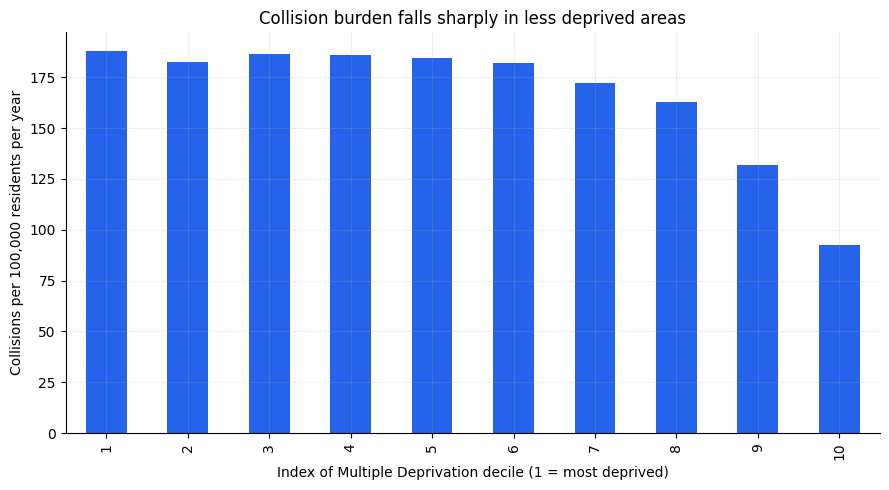

,imd_decile,collisions,raw_ksi,adjusted_expected_ksi,population_mid_2022,collisions_per_100k_resident_years,adjusted_ksi_per_100_collisions
0,1,53813,12363,12884.92,5735377,187.65,23.94
1,2,52584,11079,11410.44,5764540,182.44,21.70
2,3,54389,11093,11471.45,5839393,186.28,21.09
3,4,53717,12153,12544.40,5782194,185.80,23.35
4,5,53306,12788,13448.37,5779606,184.46,25.23
5,6,51807,12878,13438.26,5696114,181.90,25.94
6,7,49339,12118,12750.06,5740722,171.89,25.84
7,8,45988,11402,11877.38,5656824,162.59,25.83
8,9,37138,8854,9256.81,5632520,131.87,24.93
9,10,25368,6153,6425.75,5484839,92.50,25.33


In [2]:
deprivation = pd.read_csv(PUBLIC / 'deprivation_decile_summary.csv')
deprivation['imd_decile'] = deprivation.imd_decile.astype(int)
ax = deprivation.plot.bar(x='imd_decile', y='collisions_per_100k_resident_years', color=BLUE, legend=False)
ax.set(title='Collision burden falls sharply in less deprived areas', xlabel='Index of Multiple Deprivation decile (1 = most deprived)', ylabel='Collisions per 100,000 residents per year')
plt.tight_layout(); plt.show()
deprivation.round(2)

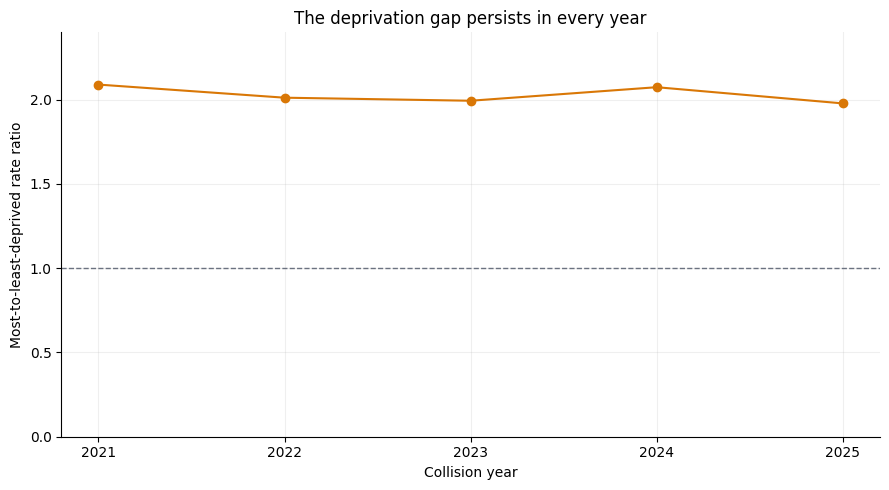

,collision_year,most_deprived,least_deprived,most_to_least_ratio
0,2021,187.47,89.70,2.09
1,2022,192.93,95.88,2.01
2,2023,188.03,94.30,1.99
3,2024,184.75,89.06,2.07
4,2025,185.10,93.57,1.98


In [3]:
gap = pd.read_csv(PUBLIC / 'deprivation_gap_by_year.csv')
ax = gap.plot(x='collision_year', y='most_to_least_ratio', marker='o', color=ORANGE, legend=False)
ax.axhline(1, color=GREY, linestyle='--', linewidth=1)
ax.set(title='The deprivation gap persists in every year', xlabel='Collision year', ylabel='Most-to-least-deprived rate ratio', xticks=gap.collision_year, ylim=(0, 2.4))
plt.tight_layout(); plt.show()
gap.round(2)

## 2. Rural collisions have greater conditional severity

This comparison asks how severe collisions are after they occur. It does not compare exposure-adjusted collision frequency.

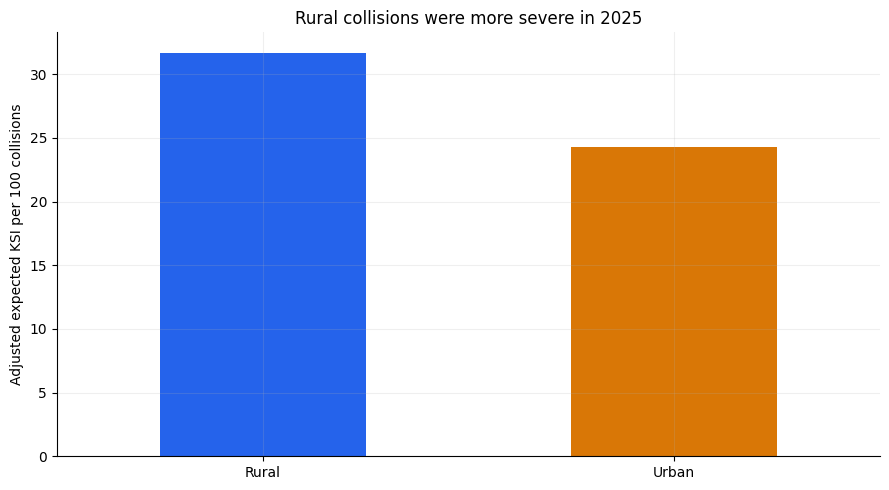

,collision_year,area_type,collisions,adjusted_expected_ksi,adjusted_ksi_per_100_collisions
12,2025,Rural,34373,10895.14,31.70
14,2025,Urban,67148,16298.43,24.27


In [4]:
area = pd.read_csv(PUBLIC / 'severity_by_urban_rural.csv')
latest = area[(area.collision_year == area.collision_year.max()) & area.area_type.isin(['Urban', 'Rural'])]
ax = latest.plot.bar(x='area_type', y='adjusted_ksi_per_100_collisions', color=[BLUE, ORANGE], legend=False, rot=0)
ax.set(title='Rural collisions were more severe in 2025', xlabel='', ylabel='Adjusted expected KSI per 100 collisions')
plt.tight_layout(); plt.show()
latest.round(2)

## 3. Speed environment requires contextual interpretation

The relationship is not monotonic: 70 mph roads have lower conditional severity than 60 mph roads. This pattern is consistent with road design and traffic separation acting alongside speed, but it does not identify their causal effects.

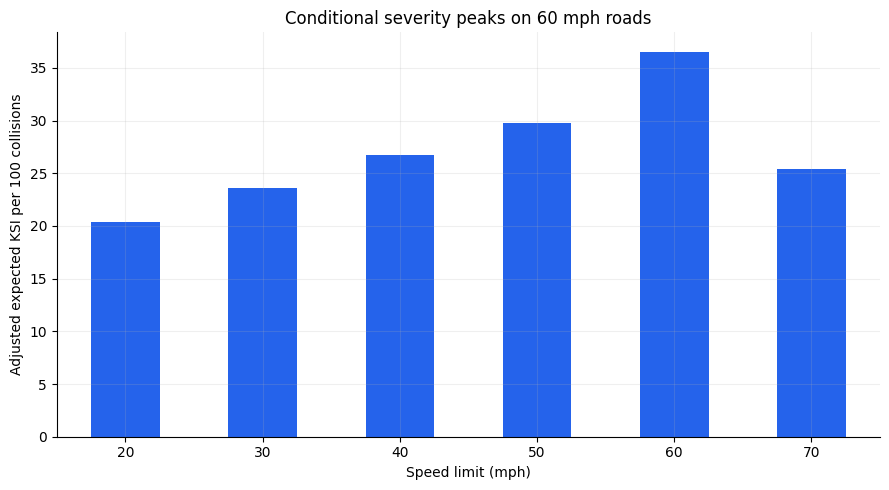

,speed_limit,collisions,adjusted_expected_ksi,adjusted_ksi_per_100_collisions
0,20,88096,17990.89,20.42
1,30,267325,63103.75,23.61
2,40,44750,11977.54,26.77
3,50,22666,6737.57,29.73
4,60,62703,22917.84,36.55
5,70,28258,7189.59,25.44


In [5]:
speed = pd.read_csv(PUBLIC / 'severity_by_speed_limit.csv')
ax = speed.plot.bar(x='speed_limit', y='adjusted_ksi_per_100_collisions', color=BLUE, legend=False, rot=0)
ax.set(title='Conditional severity peaks on 60 mph roads', xlabel='Speed limit (mph)', ylabel='Adjusted expected KSI per 100 collisions')
plt.tight_layout(); plt.show()
speed.round(2)

## Decision implications

1. Prioritise deprived urban communities for collision-occurrence diagnosis and place-based prevention.
2. Treat rural severity as a separate intervention track focused on road geometry, speed environment, emergency response, and collision type.
3. Use adjusted KSI per billion vehicle miles for local-authority risk comparisons; keep the raw measure visible for transparency.
4. Do not use the resident-normalised deprivation result as an exposure-adjusted road-risk measure.
5. Extend the analysis with road segment geometry and multivariable modelling before making causal or site-specific investment claims.